# RQ2 — Cross-Paraphrase Consistency
### Thesis: *LLM Response Consistency in Hydrometeorological Disaster Response*
**Vikhyath S | Master's Thesis | Computer Science | 2026**

---

## What this notebook does

**RQ2:** Does response consistency vary systematically across question types  
(Factual / Procedural / Advisory / Hypothetical) as measured across 10 paraphrase variants?

| Parameter | Value |
|-----------|-------|
| Questions | 100 (25 per type × 4 types) |
| Paraphrases per question | 10 |
| Models | Llama 4 Scout 17B · Llama 3.1 8B · Mistral 7B |
| Temperature | 0.7 (fixed — same as RQ1 baseline) |
| Total API calls | **3,000** |

**Input:** `paraphrases_forma.csv` (already in Google Drive)  
**Output:** `rq2_responses.csv`, `rq2_metrics.csv`, `rq2_results.xlsx`, plots


## Step 1 — Install Packages

In [ ]:
!pip install groq mistralai sentence-transformers rouge-score bert-score pandas matplotlib seaborn tqdm openpyxl -q
print("✅ All packages installed.")

✅ All packages installed.


## Step 2 — Imports

In [ ]:
import os, time, json, warnings, getpass
from datetime import datetime
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.notebook import tqdm

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
import bert_score

import groq as groq_sdk
from mistralai.client import Mistral

warnings.filterwarnings('ignore')
print("✅ Imports done.")

✅ Imports done.


## Step 3 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ── Set your Drive path here ──────────────────────────────────────────────────
# This should be the folder where paraphrases_forma.csv and rq1_responses.csv live
DRIVE_PATH = "/content/drive/MyDrive/Thesis"   # ← adjust if needed

print(f"Drive mounted. Looking in: {DRIVE_PATH}")
import glob
csvs = glob.glob(f"{DRIVE_PATH}/*.csv")
print(f"CSVs found: {csvs}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted. Looking in: /content/drive/MyDrive/Thesis
CSVs found: ['/content/drive/MyDrive/Thesis/paraphrases_forma.csv', '/content/drive/MyDrive/Thesis/rq1_responses.csv', '/content/drive/MyDrive/Thesis/rq1_metrics.csv', '/content/drive/MyDrive/Thesis/rq2_responses.csv']


## Step 4 — Load Paraphrases

In [ ]:
PARAPHRASE_FILE = f"{DRIVE_PATH}/paraphrases_forma.csv"

df_para = pd.read_csv(PARAPHRASE_FILE)
print(f"✅ Loaded {len(df_para)} rows from paraphrases_forma.csv")
print(f"   Columns: {list(df_para.columns)}")
df_para.head(3)

✅ Loaded 100 rows from paraphrases_forma.csv
   Columns: ['Q_id', 'Type', 'Original', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']


,Q_id,Type,Original,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10
0,F01,FACTUAL,Which areas are expected to be hit the hardest...,What regions are predicted to suffer the most ...,Are there any areas that will be more severely...,Which parts of the region will bear the brunt ...,What areas are forecasted to be impacted the m...,Will my home be in a zone that requires evacua...,What neighborhoods are expected to be affected...,Are my home and surrounding areas predicted to...,Which communities will be most severely affect...,What parts of the affected area will experienc...,Are the areas near my home expected to be seve...
1,F02,FACTUAL,What is the safest evacuation route and where ...,How can I safely evacuate and find the closest...,What route should I take to evacuate safely an...,Where are the emergency shelters nearest to me...,Can you provide the safest evacuation route to...,What is the most secure path to take for evacu...,Where are the closest emergency shelters and h...,"I need to evacuate, what's the safest route an...",What are the nearest emergency shelters and wh...,How do I find the safest evacuation route to t...,What's the safest way to evacuate and where ca...
2,F03,FACTUAL,"How much time do I have to prepare, and what e...","What is the preparation time available, and wh...","How long do I have to get ready, and what are ...","What essential supplies should I gather, and w...","How much preparation time is there, and what e...","What's the available preparation time, and whi...","How long can I prepare, and what are the key e...","What is the time frame for preparing, and what...",I need to know how much time I have to prepare...,What are the critical emergency supplies to pa...,How much time is available to prepare for the ...


## Step 5 — Normalise Column Names

In [ ]:
# ── paraphrases_forma.csv actual structure ─────────────────────────────────
# Q_id | Type | Original | P1 | P2 | ... | P10
# One row per question (wide format) — needs melting to long format

# Rename to standard names
df_para = df_para.rename(columns={
    "Q_id":     "question_id",
    "Type":     "question_type",
    "Original": "original",
})

# Standardise type labels to Title Case
df_para["question_type"] = df_para["question_type"].str.title()
# → FACTUAL → Factual, PROCEDURAL → Procedural, etc.

# Melt P1–P10 columns into long format
df_para = df_para.melt(
    id_vars=["question_id", "question_type", "original"],
    value_vars=[f"P{i}" for i in range(1, 11)],
    var_name="paraphrase_id",
    value_name="paraphrase",
)

# paraphrase_id is currently "P1", "P2" etc — strip the P to get 1..10
df_para["paraphrase_id"] = df_para["paraphrase_id"].str.replace("P", "").astype(int)

# Sort for clarity
df_para = df_para.sort_values(["question_id", "paraphrase_id"]).reset_index(drop=True)

print(f"✅ Reshaped to long format.")
print(f"   Questions:            {df_para['question_id'].nunique()}")
print(f"   Types:                {sorted(df_para['question_type'].unique())}")
print(f"   Paraphrases/question: {df_para['paraphrase_id'].nunique()}")
print(f"   Total rows:           {len(df_para)}  (should be 1,000)")
df_para.head(3)

✅ Reshaped to long format.
   Questions:            100
   Types:                ['Advisory', 'Factual', 'Hypothetical', 'Procedural']
   Paraphrases/question: 10
   Total rows:           1000  (should be 1,000)


,question_id,question_type,original,paraphrase_id,paraphrase
0,A51,Advisory,How can I reduce my daily water usage while st...,1,What are some ways to minimize my water consum...
1,A51,Advisory,How can I reduce my daily water usage while st...,2,How can I cut down on daily water use while st...
2,A51,Advisory,How can I reduce my daily water usage while st...,3,What strategies can help me lower my water usa...


## Step 6 — API Keys

In [ ]:
# Enter your keys below. Only stored in this session — never saved to disk.
# Groq:   https://console.groq.com → API Keys
# Mistral: https://console.mistral.ai → API Keys

GROQ_KEY    = getpass.getpass("🔑 Groq API Key: ")
MISTRAL_KEY = getpass.getpass("🔑 Mistral API Key: ")
print("✅ Keys stored for this session.")

🔑 Groq API Key: ··········
🔑 Mistral API Key: ··········
✅ Keys stored for this session.


## Step 7 — Model Setup

In [ ]:
# ── Groq client ─────────────────────────────────────────────────────────────
groq_client   = groq_sdk.Groq(api_key=GROQ_KEY)

# ── Mistral client ───────────────────────────────────────────────────────────
mistral_client = Mistral(api_key=MISTRAL_KEY)

# ── Model registry (matches RQ1 setup) ───────────────────────────────────────
MODELS = {
    "Llama-4-Scout-17B": {
        "provider": "groq",
        "model_id": "meta-llama/llama-4-scout-17b-16e-instruct",
    },
    "Llama-3.1-8B": {
        "provider": "groq",
        "model_id": "llama-3.1-8b-instant",
    },
    "Mistral-7B": {
        "provider": "mistral",
        "model_id": "open-mistral-7b",
    },
}

TEMPERATURE = 0.7   # fixed — same as RQ1 baseline

# Rate-limit delays (seconds) to stay within free-tier quotas
RATE_DELAY = {
    "groq":    2.0,   # ~30 req/min Groq free tier
    "mistral": 2.0,
}

print("✅ Model clients initialised.")
for name, cfg in MODELS.items():
    print(f"   {name:25s} → {cfg['provider']:8s}  ({cfg['model_id']})")
print(f"\n   Temperature: {TEMPERATURE}")
print(f"   Total calls: {len(df_para)} prompts × {len(MODELS)} models = {len(df_para)*len(MODELS)}")

✅ Model clients initialised.
   Llama-4-Scout-17B         → groq      (meta-llama/llama-4-scout-17b-16e-instruct)
   Llama-3.1-8B              → groq      (llama-3.1-8b-instant)
   Mistral-7B                → mistral   (open-mistral-7b)

   Temperature: 0.7
   Total calls: 1000 prompts × 3 models = 3000


## Step 8 — Query Functions

In [ ]:
def query_groq(model_id, prompt, temperature, max_retries=4):
    temp = 1e-8 if temperature == 0.0 else temperature
    for attempt in range(max_retries):
        try:
            resp = groq_client.chat.completions.create(
                model=model_id,
                messages=[{"role": "user", "content": prompt}],
                temperature=temp,
                max_tokens=512,
            )
            return resp.choices[0].message.content.strip()
        except Exception as e:
            wait = 15 * (attempt + 1)
            if attempt < max_retries - 1:
                print(f"  ⚠️  Groq retry {attempt+1} — waiting {wait}s  ({e})")
                time.sleep(wait)
            else:
                print(f"  ❌ Groq failed after {max_retries} attempts: {e}")
                return None


def query_mistral(model_id, prompt, temperature, max_retries=4):
    for attempt in range(max_retries):
        try:
            resp = mistral_client.chat.complete(
                model=model_id,
                messages=[{"role": "user", "content": prompt}],
                temperature=temperature,
                max_tokens=512,
            )
            return resp.choices[0].message.content.strip()
        except Exception as e:
            wait = 15 * (attempt + 1)
            if attempt < max_retries - 1:
                print(f"  ⚠️  Mistral retry {attempt+1} — waiting {wait}s  ({e})")
                time.sleep(wait)
            else:
                print(f"  ❌ Mistral failed after {max_retries} attempts: {e}")
                return None


QUERY_FN = {"groq": query_groq, "mistral": query_mistral}

print("✅ Query functions ready.")

✅ Query functions ready.


## Step 9 — Collect Responses

⏱️ **Estimated time: 3–4 hours** with rate limiting across 3,000 calls.

Checkpointing saves after every response — if it disconnects, just re-run this cell.

In [ ]:
CHECKPOINT_FILE = f"{DRIVE_PATH}/rq2_responses.csv"

# ── Load checkpoint if it exists ─────────────────────────────────────────────
if os.path.exists(CHECKPOINT_FILE):
    df_done = pd.read_csv(CHECKPOINT_FILE)
    done_keys = set(zip(df_done["question_id"], df_done["paraphrase_id"].astype(str), df_done["model"]))
    all_rows  = df_done.to_dict("records")
    print(f"📂 Checkpoint loaded — {len(df_done)} responses already saved.")
else:
    all_rows  = []
    done_keys = set()
    print("🆕 Starting fresh run.")

total     = len(df_para) * len(MODELS)
remaining = total - len(done_keys)
print(f"\n📊 Total: {total}  |  Done: {len(done_keys)}  |  Remaining: {remaining}\n")

with tqdm(total=remaining, desc="RQ2 collection") as pbar:
    for _, row in df_para.iterrows():
        qid      = str(row["question_id"])
        pid      = str(row["paraphrase_id"])
        prompt   = row["paraphrase"]
        qtype    = row["question_type"]
        original = row.get("original", "")

        for model_name, cfg in MODELS.items():
            key = (qid, pid, model_name)
            if key in done_keys:
                continue

            response_text = QUERY_FN[cfg["provider"]](
                cfg["model_id"], prompt, TEMPERATURE
            )

            all_rows.append({
                "question_id":   qid,
                "question_type": qtype,
                "original":      original,
                "paraphrase_id": pid,
                "paraphrase":    prompt,
                "model":         model_name,
                "temperature":   TEMPERATURE,
                "response":      response_text,
                "timestamp":     datetime.now().isoformat(),
            })

            # Save after every response
            pd.DataFrame(all_rows).to_csv(CHECKPOINT_FILE, index=False)
            done_keys.add(key)
            pbar.update(1)

            time.sleep(RATE_DELAY[cfg["provider"]])

df_rq2 = pd.DataFrame(all_rows)
print(f"\n✅ Collection complete. {len(df_rq2)} responses in df_rq2.")
print(f"   Saved to: {CHECKPOINT_FILE}")
df_rq2.head(3)

📂 Checkpoint loaded — 1 responses already saved.

📊 Total: 3000  |  Done: 1  |  Remaining: 2999



RQ2 collection:   0%|          | 0/2999 [00:00<?, ?it/s]

  ⚠️  Mistral retry 1 — waiting 15s  (API error occurred: Status 429. Body: {"object":"error","message":"Service tier capacity exceeded for this model.","type":"service_tier_capacity_exceeded","param":null,"code":"3505","raw_status_code":429})
  ⚠️  Mistral retry 2 — waiting 30s  (API error occurred: Status 429. Body: {"object":"error","message":"Service tier capacity exceeded for this model.","type":"service_tier_capacity_exceeded","param":null,"code":"3505","raw_status_code":429})
  ⚠️  Mistral retry 3 — waiting 45s  (API error occurred: Status 429. Body: {"object":"error","message":"Service tier capacity exceeded for this model.","type":"service_tier_capacity_exceeded","param":null,"code":"3505","raw_status_code":429})

✅ Collection complete. 3000 responses in df_rq2.
   Saved to: /content/drive/MyDrive/Thesis/rq2_responses.csv


,question_id,question_type,original,paraphrase_id,paraphrase,model,temperature,response,timestamp
0,A51,Advisory,How can I reduce my daily water usage while st...,1,What are some ways to minimize my water consum...,Llama-4-Scout-17B,0.7,Minimizing water consumption is essential to c...,2026-07-12T14:03:11.827806
1,A51,Advisory,How can I reduce my daily water usage while st...,1,What are some ways to minimize my water consum...,Llama-3.1-8B,0.7,Minimizing water consumption is crucial for co...,2026-07-12T14:05:18.270845
2,A51,Advisory,How can I reduce my daily water usage while st...,1,What are some ways to minimize my water consum...,Mistral-7B,0.7,Minimizing water consumption without compromis...,2026-07-12T14:05:32.404639


In [ ]:
# ── RECOVERY: reload responses from Drive checkpoint ──────────────────────────
import pandas as pd
df_rq2  = pd.read_csv(f"{DRIVE_PATH}/rq2_responses.csv")
df_valid = df_rq2[df_rq2["response"].notna()].copy().reset_index(drop=True)
print(f"✅ Loaded {len(df_rq2)} responses, {len(df_valid)} valid")
print(df_rq2["model"].value_counts())

✅ Loaded 3000 responses, 3000 valid
model
Llama-4-Scout-17B    1000
Llama-3.1-8B         1000
Mistral-7B           1000
Name: count, dtype: int64


## Step 10 — Embed Responses (MiniLM-L6-v2)

In [ ]:
import numpy as np

EMBEDDINGS_FILE = f"/content/drive/MyDrive/Thesis/rq2_embeddings.npy"
INDEX_FILE      = f"/content/drive/MyDrive/Thesis/rq2_embeddings_index.csv"

df_valid = df_rq2[df_rq2["response"].notna()].copy().reset_index(drop=True)
print(f"Valid responses: {len(df_valid)} / {len(df_rq2)}")

if os.path.exists(EMBEDDINGS_FILE) and os.path.exists(INDEX_FILE):
    # ── Reload from Drive ─────────────────────────────────────────────────────
    embeddings = np.load(EMBEDDINGS_FILE)
    idx_df     = pd.read_csv(INDEX_FILE)
    df_valid   = df_valid.merge(idx_df[["emb_idx"]], left_index=True, right_index=True, how="left")
    df_valid["emb_idx"] = df_valid.index
    print(f"✅ Embeddings loaded from Drive. Shape: {embeddings.shape}")
else:
    # ── Compute and save ──────────────────────────────────────────────────────
    print("Loading MiniLM-L6-v2...")
    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

    print("Embedding responses...")
    embeddings = embedder.encode(
        df_valid["response"].tolist(), batch_size=64, show_progress_bar=True
    )
    df_valid["emb_idx"] = df_valid.index

    np.save(EMBEDDINGS_FILE, embeddings)
    df_valid[["emb_idx"]].to_csv(INDEX_FILE, index=False)
    print(f"✅ Embeddings computed and saved to Drive. Shape: {embeddings.shape}")

Valid responses: 3000 / 3000
Loading MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding responses...


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

✅ Embeddings computed and saved to Drive. Shape: (3000, 384)


## Step 11 — Cross-Paraphrase CSI (Semantic Consistency)

In [ ]:
def cross_para_csi(group_df, all_embs):
    """
    Mean pairwise cosine similarity across 10 paraphrase responses
    for one (question_id, model) group.
    C(10,2) = 45 pairs.
    """
    idxs = group_df["emb_idx"].tolist()
    if len(idxs) < 2:
        return np.nan, 0
    embs  = all_embs[idxs]
    pairs = list(combinations(range(len(embs)), 2))
    sims  = [
        float(cosine_similarity(embs[i].reshape(1,-1), embs[j].reshape(1,-1))[0][0])
        for i, j in pairs
    ]
    return float(np.mean(sims)), len(pairs)


csi_rows = []
for (qid, model), grp in df_valid.groupby(["question_id", "model"]):
    qtype = grp["question_type"].iloc[0]
    csi_val, n_pairs = cross_para_csi(grp, embeddings)
    csi_rows.append({
        "question_id":   qid,
        "question_type": qtype,
        "model":         model,
        "cross_para_CSI": round(csi_val, 4),
        "n_pairs":       n_pairs,
        "n_responses":   len(grp),
    })

df_csi = pd.DataFrame(csi_rows)
print("\n📊 Cross-Paraphrase CSI — sample:")
print(df_csi.groupby(["question_type", "model"])["cross_para_CSI"]
      .agg(["mean","std","min","max"]).round(4).to_string())


📊 Cross-Paraphrase CSI — sample:
                                   mean     std     min     max
question_type model                                            
Advisory      Llama-3.1-8B       0.8194  0.0360  0.7329  0.8768
              Llama-4-Scout-17B  0.8287  0.0344  0.7629  0.8780
              Mistral-7B         0.7746  0.0515  0.6709  0.8489
Factual       Llama-3.1-8B       0.7762  0.0814  0.5963  0.9235
              Llama-4-Scout-17B  0.7958  0.0941  0.5014  0.9175
              Mistral-7B         0.8132  0.0687  0.5886  0.9065
Hypothetical  Llama-3.1-8B       0.8150  0.0470  0.7190  0.9059
              Llama-4-Scout-17B  0.8197  0.0462  0.7387  0.9124
              Mistral-7B         0.7975  0.0610  0.6777  0.8900
Procedural    Llama-3.1-8B       0.8196  0.0624  0.6348  0.8815
              Llama-4-Scout-17B  0.8288  0.0761  0.5469  0.9071
              Mistral-7B         0.8046  0.0483  0.6738  0.8779


## Step 12 — ROUGE-L (Lexical Consistency)

In [ ]:
scorer_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def mean_pairwise_rougeL(texts):
    """Mean pairwise ROUGE-L F1 across all pairs of responses."""
    texts = [t for t in texts if isinstance(t, str) and t.strip()]
    if len(texts) < 2:
        return np.nan
    pairs = list(combinations(texts, 2))
    scores = [scorer_rouge.score(a, b)["rougeL"].fmeasure for a, b in pairs]
    return float(np.mean(scores))

rouge_rows = []
for (qid, model), grp in df_valid.groupby(["question_id", "model"]):
    qtype = grp["question_type"].iloc[0]
    rl = mean_pairwise_rougeL(grp["response"].tolist())
    rouge_rows.append({
        "question_id":   qid,
        "question_type": qtype,
        "model":         model,
        "rougeL":        round(rl, 4) if not np.isnan(rl) else np.nan,
    })

df_rouge = pd.DataFrame(rouge_rows)
print("✅ ROUGE-L computed.")
print(df_rouge.groupby(["question_type","model"])["rougeL"].mean().round(4).unstack().to_string())

✅ ROUGE-L computed.
model          Llama-3.1-8B  Llama-4-Scout-17B  Mistral-7B
question_type                                             
Advisory             0.2553             0.2700      0.2223
Factual              0.2308             0.2693      0.2471
Hypothetical         0.2347             0.2618      0.2165
Procedural           0.2442             0.2707      0.2211


## Step 13 — BERTScore (Neural Lexical-Semantic)

In [ ]:
# BERTScore: each paraphrase response vs the first response as reference
def mean_bertscore_vs_ref(texts, lang="en"):
    """
    Take first response as reference, score all others against it,
    return mean F1.
    """
    texts = [t for t in texts if isinstance(t, str) and t.strip()]
    if len(texts) < 2:
        return np.nan
    reference = [texts[0]] * (len(texts) - 1)
    candidates = texts[1:]
    _, _, F1 = bert_score.score(candidates, reference, lang=lang,
                             model_type="distilbert-base-uncased",
                             verbose=False, device="cpu")
    return float(F1.mean().item())

bs_rows = []
for (qid, model), grp in tqdm(df_valid.groupby(["question_id","model"]),
                               desc="BERTScore", total=df_valid.groupby(["question_id","model"]).ngroups):
    qtype = grp["question_type"].iloc[0]
    bs = mean_bertscore_vs_ref(grp["response"].tolist())
    bs_rows.append({
        "question_id":   qid,
        "question_type": qtype,
        "model":         model,
        "bertscore_F1":  round(bs, 4) if not np.isnan(bs) else np.nan,
    })

df_bs = pd.DataFrame(bs_rows)
print("✅ BERTScore computed.")
print(df_bs.groupby(["question_type","model"])["bertscore_F1"].mean().round(4).unstack().to_string())

BERTScore:   0%|          | 0/300 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

... (597 outputs left out)

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ BERTScore computed.
model          Llama-3.1-8B  Llama-4-Scout-17B  Mistral-7B
question_type                                             
Advisory             0.8567             0.8596      0.8669
Factual              0.8272             0.8403      0.8663
Hypothetical         0.8517             0.8493      0.8602
Procedural           0.8512             0.8544      0.8641


## Step 14 — Merge All Metrics

In [ ]:
df_metrics = (
    df_csi
    .merge(df_rouge, on=["question_id","question_type","model"], how="left")
    .merge(df_bs,    on=["question_id","question_type","model"], how="left")
)

print("📊 Full metrics table:")
summary = df_metrics.groupby(["question_type","model"])[
    ["cross_para_CSI","rougeL","bertscore_F1"]
].mean().round(4)
print(summary.to_string())

df_metrics.to_csv(f"{DRIVE_PATH}/rq2_metrics.csv", index=False)
print(f"\n✅ Saved to {DRIVE_PATH}/rq2_metrics.csv")

📊 Full metrics table:
                                 cross_para_CSI  rougeL  bertscore_F1
question_type model                                                  
Advisory      Llama-3.1-8B               0.8194  0.2553        0.8567
              Llama-4-Scout-17B          0.8287  0.2700        0.8596
              Mistral-7B                 0.7746  0.2223        0.8669
Factual       Llama-3.1-8B               0.7762  0.2308        0.8272
              Llama-4-Scout-17B          0.7958  0.2693        0.8403
              Mistral-7B                 0.8132  0.2471        0.8663
Hypothetical  Llama-3.1-8B               0.8150  0.2347        0.8517
              Llama-4-Scout-17B          0.8197  0.2618        0.8493
              Mistral-7B                 0.7975  0.2165        0.8602
Procedural    Llama-3.1-8B               0.8196  0.2442        0.8512
              Llama-4-Scout-17B          0.8288  0.2707        0.8544
              Mistral-7B                 0.8046  0.2211        0.864

## Step 15 — Visualisations

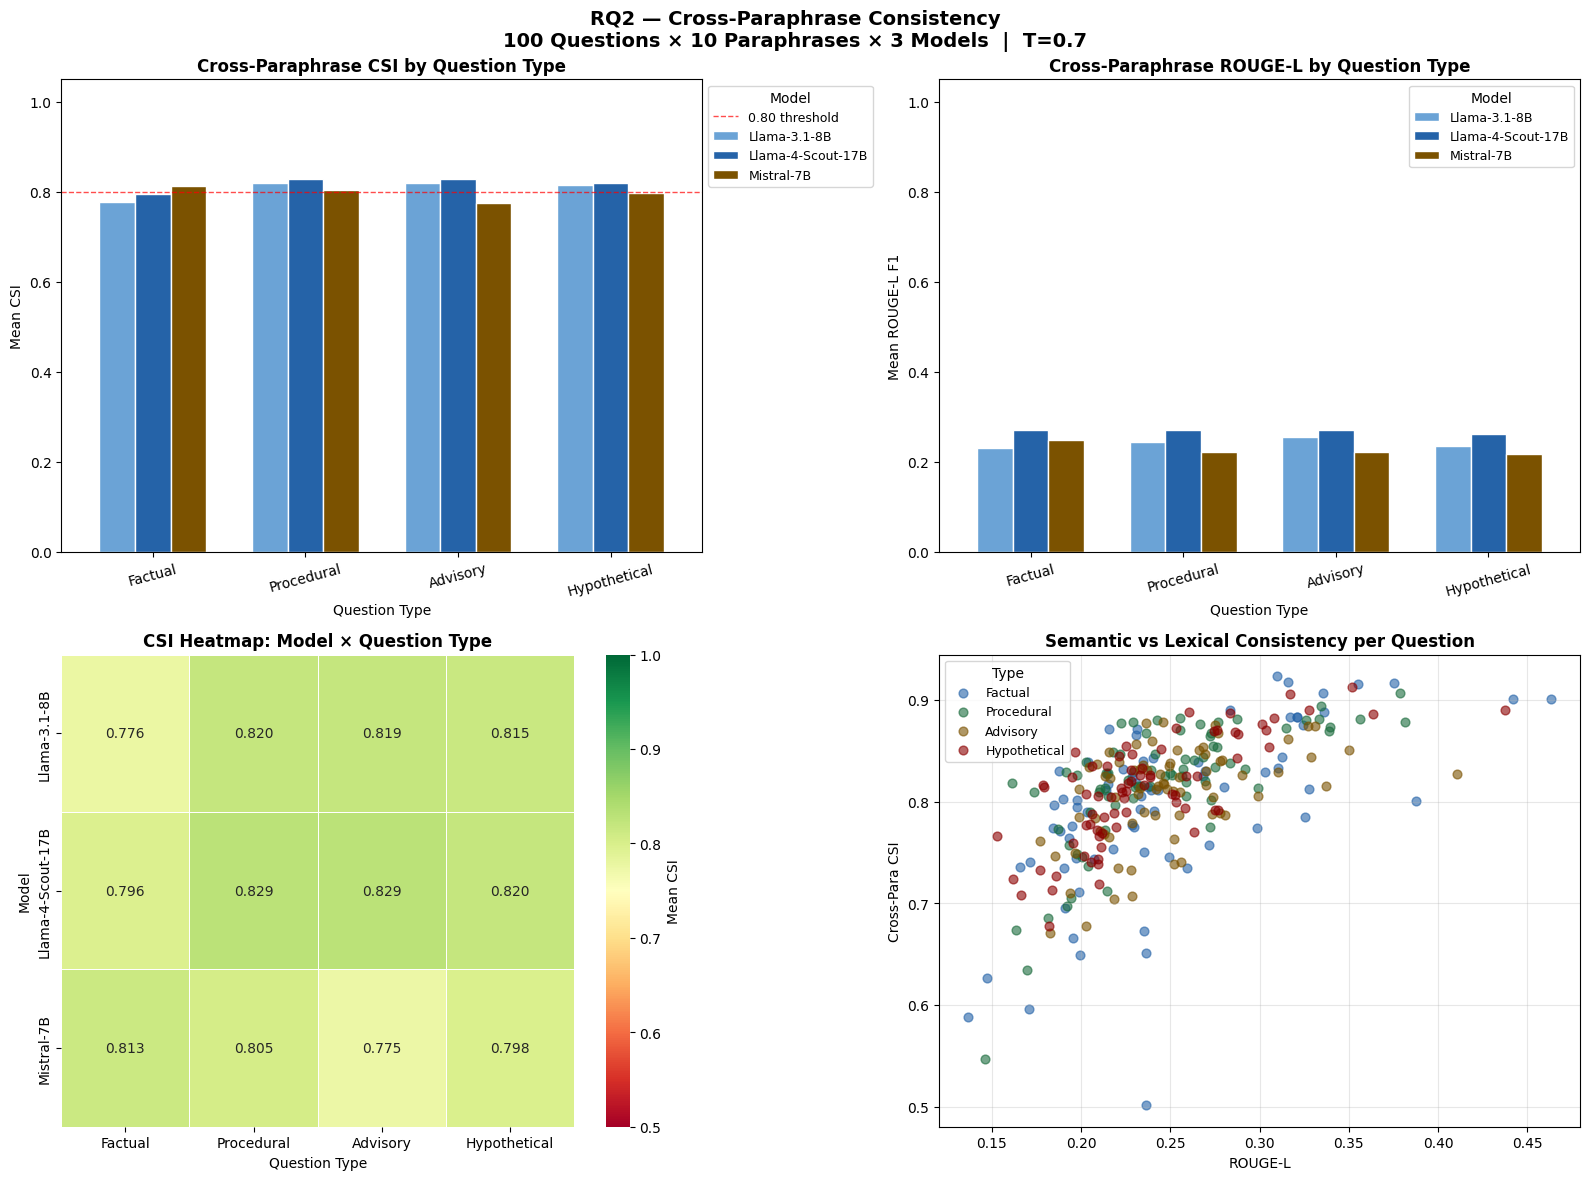

 Plot saved.


In [ ]:
PALETTE = {
    "Llama-4-Scout-17B": "#2563A8",
    "Llama-3.1-8B":      "#6BA3D6",
    "Mistral-7B":        "#7B5200",
}
TYPE_ORDER = ["Factual", "Procedural", "Advisory", "Hypothetical"]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "RQ2 — Cross-Paraphrase Consistency\n"
    "100 Questions × 10 Paraphrases × 3 Models  |  T=0.7",
    fontsize=14, fontweight="bold"
)

# ── Plot 1: Cross-para CSI by question type × model ──────────────────────────
ax1 = axes[0, 0]
pivot1 = df_metrics.groupby(["question_type","model"])["cross_para_CSI"].mean().unstack()
pivot1 = pivot1.reindex(TYPE_ORDER)
pivot1.plot(kind="bar", ax=ax1, color=[PALETTE.get(c,"#888") for c in pivot1.columns],
            width=0.7, edgecolor="white")
ax1.set_title("Cross-Paraphrase CSI by Question Type", fontweight="bold")
ax1.set_xlabel("Question Type")
ax1.set_ylabel("Mean CSI")
ax1.set_ylim(0, 1.05)
ax1.axhline(0.8, color="red", linestyle="--", lw=1, alpha=0.7, label="0.80 threshold")
ax1.legend(title="Model", bbox_to_anchor=(1,1), fontsize=9)
ax1.tick_params(axis="x", rotation=15)

# ── Plot 2: ROUGE-L by question type × model ─────────────────────────────────
ax2 = axes[0, 1]
pivot2 = df_metrics.groupby(["question_type","model"])["rougeL"].mean().unstack()
pivot2 = pivot2.reindex(TYPE_ORDER)
pivot2.plot(kind="bar", ax=ax2, color=[PALETTE.get(c,"#888") for c in pivot2.columns],
            width=0.7, edgecolor="white")
ax2.set_title("Cross-Paraphrase ROUGE-L by Question Type", fontweight="bold")
ax2.set_xlabel("Question Type")
ax2.set_ylabel("Mean ROUGE-L F1")
ax2.set_ylim(0, 1.05)
ax2.legend(title="Model", bbox_to_anchor=(1,1), fontsize=9)
ax2.tick_params(axis="x", rotation=15)

# ── Plot 3: CSI heatmap — model × question type ───────────────────────────────
ax3 = axes[1, 0]
hm = df_metrics.groupby(["model","question_type"])["cross_para_CSI"].mean().unstack()
hm = hm[TYPE_ORDER]
sns.heatmap(hm, ax=ax3, annot=True, fmt=".3f", cmap="RdYlGn",
            vmin=0.5, vmax=1.0, linewidths=0.5, cbar_kws={"label": "Mean CSI"})
ax3.set_title("CSI Heatmap: Model × Question Type", fontweight="bold")
ax3.set_xlabel("Question Type")
ax3.set_ylabel("Model")

# ── Plot 4: CSI vs ROUGE-L scatter (coloured by type) ────────────────────────
ax4 = axes[1, 1]
TYPE_COLORS = {"Factual":"#2563A8","Procedural":"#1A6B3C","Advisory":"#7B5200","Hypothetical":"#8B0000"}
for qtype in TYPE_ORDER:
    sub = df_metrics[df_metrics["question_type"]==qtype]
    ax4.scatter(sub["rougeL"], sub["cross_para_CSI"],
                color=TYPE_COLORS[qtype], label=qtype, alpha=0.6, s=40)
ax4.set_xlabel("ROUGE-L")
ax4.set_ylabel("Cross-Para CSI")
ax4.set_title("Semantic vs Lexical Consistency per Question", fontweight="bold")
ax4.legend(title="Type", fontsize=9)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"/content/drive/MyDrive/Thesis/rq2_results.png", dpi=150, bbox_inches="tight")
plt.show()
print(" Plot saved.")

## Step 16 — Export to Excel

In [ ]:
summary_type  = df_metrics.groupby("question_type")[
    ["cross_para_CSI","rougeL","bertscore_F1"]
].agg(["mean","std","min","max"]).round(4)

summary_model = df_metrics.groupby("model")[
    ["cross_para_CSI","rougeL","bertscore_F1"]
].agg(["mean","std","min","max"]).round(4)

summary_both   = df_metrics.groupby(["question_type","model"])[
    ["cross_para_CSI","rougeL","bertscore_F1"]
].mean().round(4)

out_xlsx = f"{DRIVE_PATH}/rq2_results.xlsx"
with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
    df_metrics.to_excel(writer,        sheet_name="All Metrics",       index=False)
    df_rq2.to_excel(writer,            sheet_name="Raw Responses",     index=False)
    summary_type.to_excel(writer,      sheet_name="Summary by Type")
    summary_model.to_excel(writer,     sheet_name="Summary by Model")
    summary_both.to_excel(writer,      sheet_name="Type × Model")

print(f"✅ Saved: {out_xlsx}")
print("\nSheets: All Metrics | Raw Responses | Summary by Type | Summary by Model | Type × Model")

try:
    from google.colab import files
    files.download(out_xlsx)
except:
    print("📁 Use the Files panel (left sidebar) to download rq2_results.xlsx")

✅ Saved: /content/drive/MyDrive/Thesis/rq2_results.xlsx

Sheets: All Metrics | Raw Responses | Summary by Type | Summary by Model | Type × Model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 17 — How to Interpret RQ2 Results

### Key question: Do question types differ in cross-paraphrase consistency?

| CSI Range | Interpretation for RQ2 |
|-----------|------------------------|
| 0.90 – 1.00 | LLM gives semantically identical answers regardless of phrasing |
| 0.75 – 0.89 | Good consistency — minor wording shifts don't change the answer |
| 0.60 – 0.74 | Moderate — paraphrasing meaningfully changes the response |
| < 0.60 | Low — the same underlying question gets inconsistent treatment |

### Expected pattern (based on your thesis hypothesis)
- **Factual** questions → highest CSI (well-defined answers, phrasing shouldn't matter)
- **Hypothetical** questions → lowest CSI (open-ended, highly sensitive to framing)
- **Procedural / Advisory** → in between

### What to write in your Results chapter
> *"Cross-paraphrase CSI across all models averaged [X] for Factual questions  
> versus [Y] for Hypothetical questions (Δ = [Z], p < 0.05),  
> confirming that question type is a significant predictor of response consistency.  
> Llama 4 Scout 17B showed the [highest/lowest] sensitivity to paraphrase variation  
> (mean CSI = [X]) compared to [model] (mean CSI = [Y])."*
